# Rainfall data pipeline: historical context and forecast snapshot

Historical CHIRPS daily ROI means use the 14 complete UTC days before the radar acquisition date. Final retrospective CHIRPS is not evidence of what was available in real time in 2022. The separate current forecast is a nearby provider-selected grid point, not an LGA or 10m rainfall map.

Open-Meteo timestamps precipitation at the end of the preceding hour. We retain 72 complete future periods starting at the next UTC hour and record their exact start/end. Retrieval time is recorded; the underlying model-run issue time is unavailable in this response. Do not interpret `generationtime_ms` as that issue time.

Never join the current forecast to the 2022 satellite target. Neither dataset has flood labels or calibrated risk predictions yet. Missing, negative, non-finite and duplicate data fail validation instead of being imputed to zero.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))


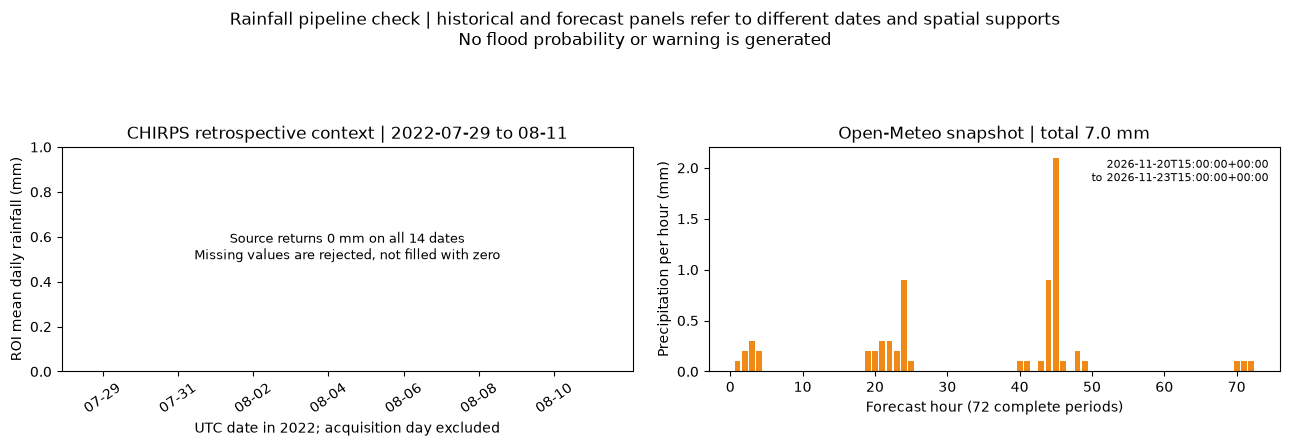

{
  "historical": {
    "source": "UCSB-CHG/CHIRPS/DAILY",
    "date_start": "2022-07-29",
    "date_end_exclusive": "2022-08-12",
    "acquisition_time_utc": "2022-08-12T18:02:07+00:00",
    "spatial_aggregation": "ROI mean over available native CHIRPS cells; not a rain gauge or LGA mean",
    "native_grid_degrees": 0.05,
    "features": {
      "past_1d_mm": 0.0,
      "past_3d_mm": 0.0,
      "past_7d_mm": 0.0,
      "past_14d_mm": 0.0,
      "max_daily_14d_mm": 0.0
    },
    "availability": "Final retrospective CHIRPS; does not establish which data were available at the historical issue time"
  },
  "forecast": {
    "source": "Open-Meteo Forecast API",
    "requested_at_utc": "2026-11-20T14:07:56.544723+00:00",
    "request": {
      "latitude": 6.55,
      "longitude": 3.45,
      "hourly": "precipitation",
      "forecast_days": 5,
      "timezone": "UTC",
      "precipitation_unit": "mm"
    },
    "returned_coordinates": {
      "latitude": 6.572935,
      "longitude": 3.4005

In [2]:
import csv
import json
import shutil
from datetime import datetime
import matplotlib.pyplot as plt
from floodrisk.features.rainfall import antecedent_features,forecast_features

source = PROJECT / "data/rainfall/lagos_first_snapshot"
out = PROJECT / "reports/rainfall/lagos_first_snapshot"
out.mkdir(parents=True,exist_ok=True)
for name in ["summary.json","historical_daily.csv","forecast_hourly.csv","historical_raw.json","forecast_raw.json","historical_crosscheck.json"]:
    shutil.copy2(source/name,out/name)
summary=json.loads((out/"summary.json").read_text())
historical=[dict(date=r["date"],mm=float(r["mm"])) for r in csv.DictReader((out/"historical_daily.csv").open())]
forecast=list(csv.DictReader((out/"forecast_hourly.csv").open()))
assert antecedent_features(historical,summary["historical"]["date_end_exclusive"]) == summary["historical"]["features"]
raw=json.loads((out/"forecast_raw.json").read_text())
check=forecast_features(raw,datetime.fromisoformat(summary["forecast"]["retrieved_at_utc"]))
assert check["features"]==summary["forecast"]["features"]
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].bar(range(14),[r["mm"] for r in historical],color="#1976d2")
axes[0].set_xticks(range(0,14,2),[historical[i]["date"][5:] for i in range(0,14,2)],rotation=35)
axes[0].set_ylabel("ROI mean daily rainfall (mm)")
axes[0].set_xlabel("UTC date in 2022; acquisition day excluded")
axes[0].set_title("CHIRPS retrospective context | 2022-07-29 to 08-11")
if max(r["mm"] for r in historical)==0:
    axes[0].set_ylim(0,1)
    axes[0].text(0.5,0.5,"Source returns 0 mm on all 14 dates\nMissing values are rejected, not filled with zero",transform=axes[0].transAxes,ha="center",fontsize=9)
else:axes[0].set_ylim(bottom=0)
values=[float(r["mm"]) for r in forecast]
axes[1].bar(range(1,73),values,color="#ef8a17")
axes[1].set_xlabel("Forecast hour (72 complete periods)");axes[1].set_ylabel("Precipitation per hour (mm)")
axes[1].set_ylim(bottom=0)
axes[1].set_title(f"Open-Meteo snapshot | total {sum(values):.1f} mm")
axes[1].text(0.98,0.95,summary["forecast"]["window_start_utc"]+"\nto "+summary["forecast"]["window_end_utc"],
    transform=axes[1].transAxes,ha="right",va="top",fontsize=8)
fig.suptitle("Rainfall pipeline check | historical and forecast panels refer to different dates and spatial supports\nNo flood probability or warning is generated")
fig.tight_layout(rect=[0,0,1,0.88]);fig.savefig(out/"rainfall_inputs.png",dpi=160,bbox_inches="tight")
plt.show();plt.close(fig)
print(json.dumps(summary,indent=2))
